# Final Project 2, Part 1: Data Integration and Preparation for PCA
**DO YOU EVEN LOAF? Does Seoul Bulk or Cut?** | CDS 303

In this notebook we combine our primary dataset (estimated sales by 행정동) with our supplementary datasets
(stores, fitness center licenses, resident and workplace population, and 자치구 obesity rates) into one table
where **each row is one 행정동 in 2025**. We then prepare the variables for PCA.

All datasets were translated from Korean to English by our team without changing any values.
See `data/README.md` for sources and download instructions.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Reproducible settings
RANDOM_STATE = 2000
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Paths are relative to the notebooks/ folder
RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# We only use 2025 data (Q1 to Q4)
QUARTERS_2025 = [20251, 20252, 20253, 20254]

# Our definitions of "gym" and "bakery" in the Seoul business categories
BAKERY = ["Bakery"]
GYM = ["Sports Club", "Sports Instruction"]   # Golf Driving Range is excluded on purpose

KEY = "Administrative_Dong_Code"

def read(name):
    return pd.read_csv(RAW / name, encoding="utf-8-sig")

## 1. Load the datasets and keep only 2025

The Seoul Commercial District Analysis Service files cover 2021 to 2026, so we filter to the four 2025 quarters.

In [2]:
sales = read("Seoul_Estimated_Sales_by_Dong.csv.zip")   # zipped to stay under GitHub's 25 MB upload limit
stores = read("Seoul_Stores_by_Dong.csv")
resident = read("Seoul_Resident_Population_by_Dong.csv")
workplace = read("Seoul_Workplace_Population_by_Dong.csv")
gyms = read("Seoul_Fitness_Center_Licenses.csv")
obesity = read("Seoul_Obesity_by_Borough_2025.csv")
boundaries = gpd.read_file(RAW / "Seoul_Dong_Boundaries_ver20250701.geojson")

def keep_2025(df):
    return df[df["Standard_Year_Quarter_Code"].isin(QUARTERS_2025)].copy()

sales, stores, resident, workplace = map(keep_2025, [sales, stores, resident, workplace])

summary = pd.DataFrame({
    "rows (2025)": [len(sales), len(stores), len(resident), len(workplace)],
    "행정동": [d[KEY].nunique() for d in [sales, stores, resident, workplace]],
    "quarters": [sorted(d["Standard_Year_Quarter_Code"].unique()) for d in [sales, stores, resident, workplace]],
}, index=["sales", "stores", "resident population", "workplace population"])
summary

,rows (2025),행정동,quarters
sales,67113,425,"[20251, 20252, 20253, 20254]"
stores,141218,425,"[20251, 20252, 20253, 20254]"
resident population,1700,425,"[20251, 20252, 20253, 20254]"
workplace population,1656,414,"[20251, 20252, 20253, 20254]"


## 2. Aggregate each dataset to one row per 행정동

The raw files have one row per 행정동 × business category × quarter. If we merged them like this, rows would multiply.
So we first reduce every dataset to **one row per 행정동**:

- **Sales are flows**, so we **sum** the four quarters (total transactions in 2025).
- **Stores and population are stocks**, so we **average** the four quarters (10 bakeries every quarter means 10 bakeries, not 40).

### 2.1 Sales

In [3]:
count_cols = [c for c in sales.columns if c.endswith("_Sales_Count")] + ["Monthly_Sales_Count"]
count_cols = list(dict.fromkeys(count_cols))

# Total transactions over ALL categories (denominator for the transaction shares)
dong_total = (sales.groupby(KEY)["Monthly_Sales_Count"].sum()
              .rename("all_transactions"))

def category_totals(categories, prefix):
    sub = sales[sales["Service_Business_Name"].isin(categories)]
    out = sub.groupby(KEY)[count_cols].sum()
    out.columns = [f"{prefix}_{c.replace('_Sales_Count', '').replace('Monthly', 'total').lower()}" for c in out.columns]
    return out

bakery_sales = category_totals(BAKERY, "bakery")
gym_sales = category_totals(GYM, "gym")

dong_names = sales.drop_duplicates(KEY).set_index(KEY)["Administrative_Dong_Name"]
sales_dong = (pd.concat([dong_names, dong_total], axis=1)
              .join(bakery_sales).join(gym_sales))

print("행정동 rows:", len(sales_dong))
print("행정동 with bakery sales:", sales_dong["bakery_total"].notna().sum())
print("행정동 with gym sales:", sales_dong["gym_total"].notna().sum())
sales_dong[["Administrative_Dong_Name", "all_transactions", "bakery_total", "gym_total"]].head()

행정동 rows: 425
행정동 with bakery sales: 379
행정동 with gym sales: 397


,Administrative_Dong_Name,all_transactions,bakery_total,gym_total
Administrative_Dong_Code,,,,
11740700,Dunchon 2-dong,4419911,239070.0,5343.0
11740690,Dunchon 1-dong,3937460,243276.0,5151.0
11740685,Gil-dong,19340881,494388.0,6259.0
11740660,Seongnae 3-dong,12011711,1007086.0,20948.0
11740650,Seongnae 2-dong,8995538,271449.0,3146.0


**Note on gender and age columns.** The gender and age counts do not always add up to the total number of transactions
(some card transactions have no customer information, for example corporate cards). So when we calculate the female share
or the 20s and 30s share, we divide by the transactions where gender or age is known, not by the total.

In [4]:
gap = (sales["Male_Sales_Count"] + sales["Female_Sales_Count"] - sales["Monthly_Sales_Count"]).abs()
print(f"Rows where male + female != total: {(gap > 0).mean():.1%}")

Rows where male + female != total: 63.5%


### 2.2 Stores

In [5]:
store_q = stores.groupby([KEY, "Standard_Year_Quarter_Code"])
all_stores = (stores.groupby([KEY, "Standard_Year_Quarter_Code"])["Total_Store_Count"].sum()
              .groupby(KEY).mean().rename("all_stores"))
bakery_stores = (stores[stores["Service_Business_Name"].isin(BAKERY)]
                 .groupby([KEY, "Standard_Year_Quarter_Code"])["Total_Store_Count"].sum()
                 .groupby(KEY).mean().rename("bakery_stores"))
gym_stores = (stores[stores["Service_Business_Name"].isin(GYM)]
              .groupby([KEY, "Standard_Year_Quarter_Code"])["Total_Store_Count"].sum()
              .groupby(KEY).mean().rename("gym_stores"))

stores_dong = pd.concat([all_stores, bakery_stores, gym_stores], axis=1).fillna({"bakery_stores": 0, "gym_stores": 0})
print("행정동 rows:", len(stores_dong))
stores_dong.describe().round(1)

행정동 rows: 425


,all_stores,bakery_stores,gym_stores
count,425.0,425.0,425.0
mean,1498.2,17.0,33.9
std,1412.0,14.9,28.5
min,175.0,0.0,1.0
25%,718.2,8.0,15.5
50%,1147.8,13.2,25.8
75%,1640.8,20.5,45.2
max,12070.8,123.8,229.5


### 2.3 Fitness center licenses (spatial join)

The license data has no 행정동 code, only addresses and coordinates. Addresses use 법정동 (legal dongs), which do not match the
행정동 (administrative dongs) in our sales data, so we place each gym inside a 행정동 using its coordinates and the 2025 행정동 boundaries.

Steps:
1. Keep gyms that were **operating at any point in 2025** (licensed on or before 2025-12-31 and not closed before 2025-01-01).
2. Drop gyms with no coordinates.
3. Convert gym coordinates (EPSG:5174) to the boundary coordinate system (EPSG:4326).
4. Fix three 행정동 that were reorganized in the boundary file (see crosswalk below).
5. Count gyms per 행정동. 행정동 with no gyms get 0.

In [6]:
# Dates are YYYY-MM-DD; blank closure date = never closed
gyms["License_Date"] = pd.to_datetime(gyms["License_Date"].str.strip(), format="%Y-%m-%d", errors="coerce")
gyms["Closure_Date"] = pd.to_datetime(gyms["Closure_Date"].str.strip(), format="%Y-%m-%d", errors="coerce")

operating_2025 = gyms[(gyms["License_Date"] <= "2025-12-31") &
                      (gyms["Closure_Date"].isna() | (gyms["Closure_Date"] >= "2025-01-01"))].copy()
operating_2025["x"] = pd.to_numeric(operating_2025["Coordinate_X"], errors="coerce")
operating_2025["y"] = pd.to_numeric(operating_2025["Coordinate_Y"], errors="coerce")
no_coords = operating_2025[["x", "y"]].isna().any(axis=1).sum()
operating_2025 = operating_2025.dropna(subset=["x", "y"])

print("All license records:", len(gyms))
print("Operating in 2025:", len(operating_2025) + no_coords)
print("Dropped (no coordinates):", no_coords)
print("Used in spatial join:", len(operating_2025))

All license records: 7370
Operating in 2025: 4561
Dropped (no coordinates): 87
Used in spatial join: 4474


In [7]:
# Crosswalk: the boundary file (ver20250701) uses newer 행정동 than the Seoul sales data.
# We map the new codes back to the old ones and merge their polygons.
CROSSWALK = {
    11230515: 11230536,  # Sinseol-dong  -> Yongsin-dong (Dongdaemun-gu)
    11230533: 11230536,  # Yongdu-dong   -> Yongsin-dong (Dongdaemun-gu)
    11680675: 11680740,  # Gaepo 3-dong  -> Irwon 2-dong (Gangnam-gu)
    11740525: 11740520,  # Sangil 1-dong -> Sangil-dong (Gangdong-gu)
    11740526: 11740520,  # Sangil 2-dong -> Sangil-dong (Gangdong-gu)
}
boundaries[KEY] = boundaries["adm_cd2"].str[:8].astype(int).replace(CROSSWALK)
boundaries = boundaries.dissolve(by=KEY, as_index=False)[[KEY, "sgg", "sggnm", "geometry"]]

missing_in_boundaries = set(sales_dong.index) - set(boundaries[KEY])
print("Boundary polygons after crosswalk:", len(boundaries))
print("Sales 행정동 without a boundary:", len(missing_in_boundaries))

Boundary polygons after crosswalk: 425
Sales 행정동 without a boundary: 0


In [8]:
gym_points = gpd.GeoDataFrame(operating_2025,
                              geometry=gpd.points_from_xy(operating_2025["x"], operating_2025["y"]),
                              crs="EPSG:5174").to_crs(boundaries.crs)
joined = gpd.sjoin(gym_points, boundaries[[KEY, "geometry"]], how="left", predicate="within")

print("Gyms not inside any 행정동:", joined[KEY].isna().sum())
print("Gyms matched to more than one 행정동:", joined.index.duplicated().sum())

gyms_dong = joined.groupby(KEY).size().rename("licensed_gyms")
gyms_dong = gyms_dong.reindex(sales_dong.index, fill_value=0)
print("행정동 with at least one licensed gym:", (gyms_dong > 0).sum())

Gyms not inside any 행정동: 0
Gyms matched to more than one 행정동: 0
행정동 with at least one licensed gym: 417


### 2.4 Resident and workplace population

In [9]:
resident_dong = resident.groupby(KEY)["Total_Resident_Population"].mean().rename("resident_pop")
workplace_dong = workplace.groupby(KEY)["Total_Workplace_Population"].mean().rename("workplace_pop")
population_dong = pd.concat([resident_dong, workplace_dong], axis=1)

# Workplace share: high = office area, low = residential area
population_dong["workplace_share"] = (population_dong["workplace_pop"] /
                                      (population_dong["workplace_pop"] + population_dong["resident_pop"]))
print("행정동 with resident population:", population_dong["resident_pop"].notna().sum())
print("행정동 with workplace population:", population_dong["workplace_pop"].notna().sum())

행정동 with resident population: 425
행정동 with workplace population: 414


### 2.5 Obesity (자치구 level)

Obesity is only available for the 25 자치구. The first 5 digits of a 행정동 code are its 자치구 code,
and the boundary file gives us the 자치구 code → name lookup, so we can attach each 행정동 to its 자치구.

In [10]:
obesity = obesity[obesity["Borough"] != "Total"].copy()   # drop the Seoul total row
obesity["Obesity_Rate_BMI25plus_pct_2025"] = obesity["Obesity_Rate_BMI25plus_pct_2025"].astype(float)

borough_lookup = boundaries.drop_duplicates("sgg")[["sgg", "sggnm"]].rename(
    columns={"sgg": "Borough_Code", "sggnm": "Borough"})
borough_lookup["Borough_Code"] = borough_lookup["Borough_Code"].astype(int)
obesity = obesity.merge(borough_lookup, on="Borough", how="left", validate="one_to_one")

print("자치구 in obesity data:", len(obesity))
print("자치구 without a code match:", obesity["Borough_Code"].isna().sum())
obesity[["Borough_Code", "Borough", "Obesity_Rate_BMI25plus_pct_2025"]].head()

자치구 in obesity data: 25
자치구 without a code match: 0


,Borough_Code,Borough,Obesity_Rate_BMI25plus_pct_2025
0,11110,Jongno-gu,28.6
1,11140,Jung-gu,26.5
2,11170,Yongsan-gu,22.9
3,11200,Seongdong-gu,29.0
4,11215,Gwangjin-gu,30.9


## 3. Merge everything into one table

We start from the sales table and join each dataset on the 행정동 code.
`validate="one_to_one"` makes pandas raise an error if any 행정동 appears twice, so the merge cannot duplicate rows.
Obesity is joined with `validate="many_to_one"` because many 행정동 share one 자치구.

In [11]:
dong = sales_dong.reset_index()
dong["Borough_Code"] = dong[KEY] // 1000   # first 5 digits

n_start = len(dong)
dong = dong.merge(stores_dong.reset_index(), on=KEY, how="left", validate="one_to_one")
dong = dong.merge(gyms_dong.reset_index(), on=KEY, how="left", validate="one_to_one")
dong = dong.merge(population_dong.reset_index(), on=KEY, how="left", validate="one_to_one")
dong = dong.merge(obesity[["Borough_Code", "Borough", "Obesity_Rate_BMI25plus_pct_2025"]],
                  on="Borough_Code", how="left", validate="many_to_one")

checks = pd.Series({
    "rows before merge": n_start,
    "rows after merge": len(dong),
    "duplicate 행정동 codes": dong[KEY].duplicated().sum(),
    "자치구 represented": dong["Borough"].nunique(),
    "missing store data": dong["all_stores"].isna().sum(),
    "missing obesity": dong["Obesity_Rate_BMI25plus_pct_2025"].isna().sum(),
    "missing resident population": dong["resident_pop"].isna().sum(),
    "missing workplace population": dong["workplace_pop"].isna().sum(),
})
checks

rows before merge               425
rows after merge                425
duplicate 행정동 codes               0
자치구 represented                  25
missing store data                0
missing obesity                   0
missing resident population       0
missing workplace population     11
dtype: int64

In [12]:
assert len(dong) == n_start, "Merge changed the number of rows"
assert not dong[KEY].duplicated().any(), "Duplicate 행정동 after merge"
assert dong["Obesity_Rate_BMI25plus_pct_2025"].notna().all(), "Some 행정동 have no obesity value"
print("All merge checks passed.")

All merge checks passed.


## 4. Build the PCA variables

We use **shares and densities instead of raw counts**. Raw counts mostly measure how big or busy a 행정동 is,
so PC1 would just separate big and small 행정동. Shares describe the *pattern* of activity instead.

In [13]:
def share(num, den):
    return dong[num] / dong[den]

# Activity: how much of the 행정동's transactions go to bakeries and gyms
dong["bakery_txn_share"] = share("bakery_total", "all_transactions")
dong["gym_txn_share"] = share("gym_total", "all_transactions")

# Timing: when people go to the gym
dong["gym_morning_share"] = share("gym_time_06-11", "gym_total")
dong["gym_evening_share"] = (dong["gym_time_17-21"] + dong["gym_time_21-24"]) / dong["gym_total"]

# Customers: who buys (denominators are transactions with known age / gender)
bakery_age_known = dong[[c for c in dong.columns if c.startswith("bakery_age_")]].sum(axis=1)
dong["bakery_young_share"] = (dong["bakery_age_20s"] + dong["bakery_age_30s"]) / bakery_age_known
dong["gym_female_share"] = dong["gym_female"] / (dong["gym_male"] + dong["gym_female"])

# Supply: how many bakeries and gyms exist relative to all stores
dong["bakery_store_share"] = share("bakery_stores", "all_stores")
dong["gym_density"] = dong["licensed_gyms"] / dong["all_stores"] * 1000   # licensed gyms per 1,000 stores

PCA_VARS = ["bakery_txn_share", "gym_txn_share", "gym_morning_share", "gym_evening_share",
            "bakery_young_share", "gym_female_share", "bakery_store_share", "gym_density"]
CONTEXT_VARS = ["resident_pop", "workplace_pop", "workplace_share", "Obesity_Rate_BMI25plus_pct_2025"]

dong[PCA_VARS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
bakery_txn_share,379.0,0.034,0.026,0.000,0.015,0.027,0.043,0.154
gym_txn_share,397.0,0.001,0.004,0.000,0.000,0.001,0.001,0.065
gym_morning_share,397.0,0.082,0.053,0.000,0.047,0.080,0.108,0.364
gym_evening_share,397.0,0.533,0.112,0.169,0.474,0.532,0.591,1.000
bakery_young_share,379.0,0.339,0.107,0.116,0.261,0.321,0.398,0.682
gym_female_share,397.0,0.532,0.123,0.000,0.460,0.532,0.606,1.000
bakery_store_share,425.0,0.012,0.005,0.000,0.009,0.012,0.015,0.044
gym_density,425.0,7.042,3.558,0.000,4.426,6.735,9.608,16.859


## 5. Missing values

There are no empty cells in the original files. The missing values come from the structure of the data:
a 행정동 with no bakery or no gym transactions has no row for that category, so its bakery or gym shares cannot be calculated.

We **drop** these 행정동 instead of imputing them. Imputing would invent bakery or gym customers in places where there are none.
Workplace population is missing for some 행정동, but it is not a PCA input, so we keep those rows.

In [14]:
missing = dong[PCA_VARS].isna()
print("행정동 with at least one missing PCA variable:", missing.any(axis=1).sum())
print(missing.sum().rename("missing values per variable").to_string())

no_bakery = dong["bakery_total"].isna() | (dong["bakery_total"] == 0)
no_gym = dong["gym_total"].isna() | (dong["gym_total"] == 0)
print()
print("No bakery transactions:", no_bakery.sum())
print("No gym transactions:", no_gym.sum())
print("Neither:", (no_bakery & no_gym).sum())

행정동 with at least one missing PCA variable: 60
bakery_txn_share      46
gym_txn_share         28
gym_morning_share     28
gym_evening_share     28
bakery_young_share    46
gym_female_share      28
bakery_store_share     0
gym_density            0

No bakery transactions: 46
No gym transactions: 28
Neither: 14


In [15]:
dong_clean = dong.dropna(subset=PCA_VARS).copy()
dong_clean = dong_clean[np.isfinite(dong_clean[PCA_VARS]).all(axis=1)]

print(f"행정동 kept for PCA: {len(dong_clean)} of {len(dong)} "
      f"({len(dong) - len(dong_clean)} dropped)")
print("자치구 still represented:", dong_clean["Borough"].nunique())

행정동 kept for PCA: 365 of 425 (60 dropped)
자치구 still represented: 25


## 6. Check distributions and transform skewed variables

PCA is based on variance, so a few extreme 행정동 can pull a whole component toward them.
We check the skewness of each variable and transform the ones that are right-skewed:

- **Moderate skew (1 < skew ≤ 3): square root.**
- **Extreme skew (skew > 3): natural log.**

We tried `log1p` first, but our shares are very small numbers (for example 0.001), and `log1p(x)` is almost equal to `x`
for small values, so it did not reduce the skew at all. A plain log on the gym share overcorrects the moderate variables,
so we use the gentler square root for those.

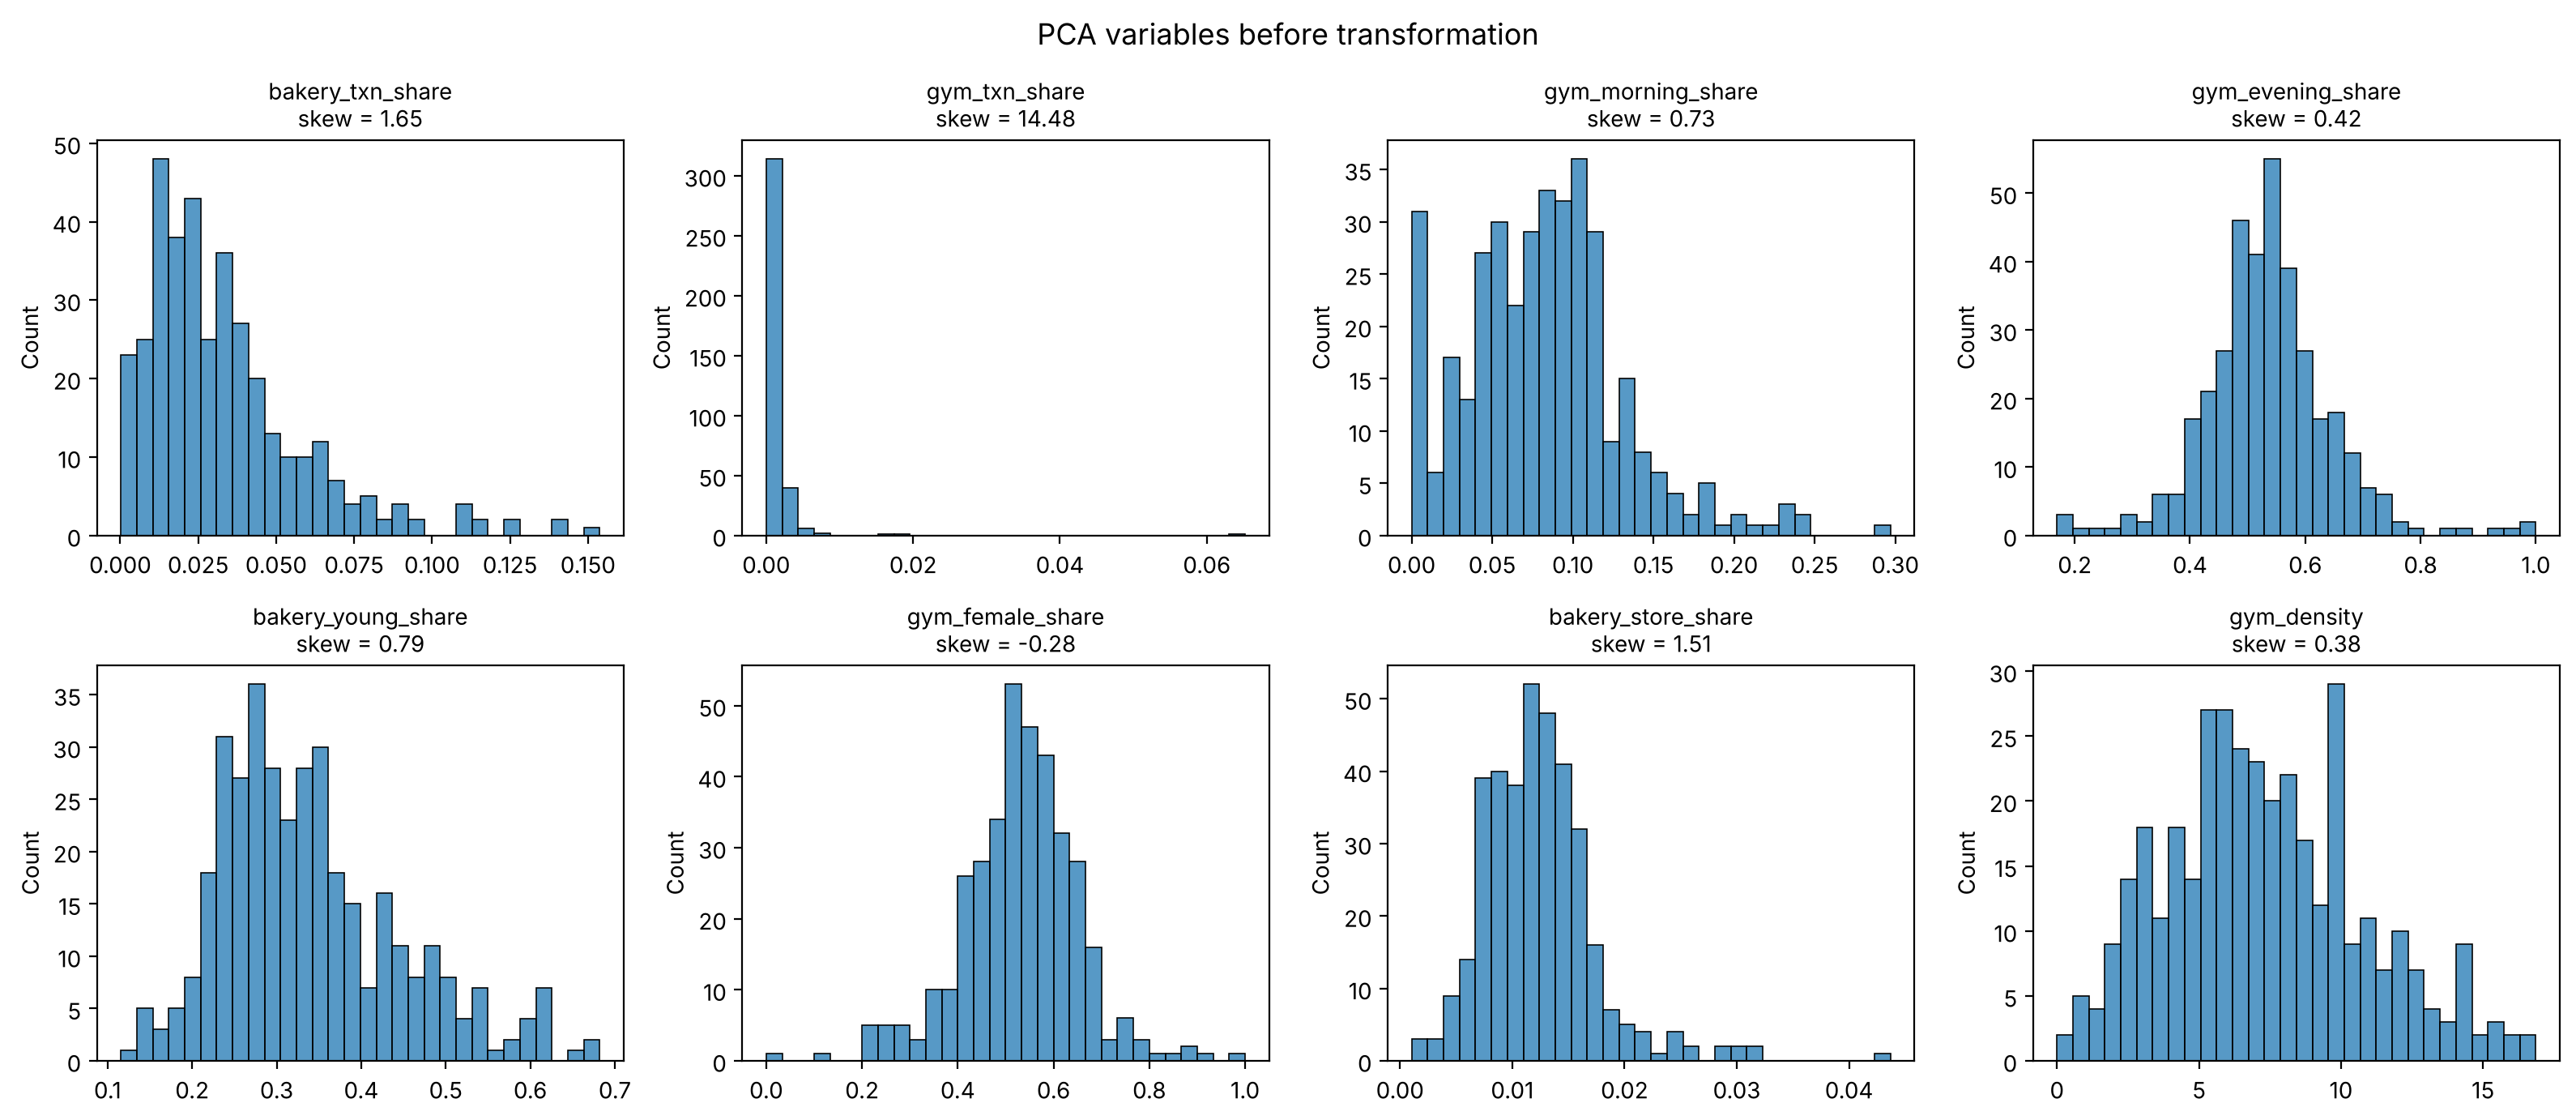

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, PCA_VARS):  # raw values, before any transformation
    sns.histplot(dong_clean[col], ax=ax, bins=30)
    ax.set_title(f"{col}\nskew = {dong_clean[col].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
plt.suptitle("PCA variables before transformation", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES / "p1_distributions_before.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
skewness = dong_clean[PCA_VARS].skew()
SQRT_VARS = skewness[(skewness > 1) & (skewness <= 3)].index.tolist()
LOG_VARS = skewness[skewness > 3].index.tolist()
print("Square root (1 < skew <= 3):", SQRT_VARS)
print("Natural log (skew > 3):", LOG_VARS)

X = dong_clean[PCA_VARS].copy()
for col in SQRT_VARS:
    X[col] = np.sqrt(X[col])
for col in LOG_VARS:
    assert (X[col] > 0).all(), f"{col} has zeros, log is undefined"
    X[col] = np.log(X[col])

transform = {c: "sqrt" if c in SQRT_VARS else "log" if c in LOG_VARS else "none" for c in PCA_VARS}
pd.DataFrame({"transformation": transform, "skew before": skewness.round(2), "skew after": X.skew().round(2)})

Square root (1 < skew <= 3): ['bakery_txn_share', 'bakery_store_share']
Natural log (skew > 3): ['gym_txn_share']


,transformation,skew before,skew after
bakery_txn_share,sqrt,1.65,0.48
gym_txn_share,log,14.48,-0.84
gym_morning_share,none,0.73,0.73
gym_evening_share,none,0.42,0.42
bakery_young_share,none,0.79,0.79
gym_female_share,none,-0.28,-0.28
bakery_store_share,sqrt,1.51,0.37
gym_density,none,0.38,0.38


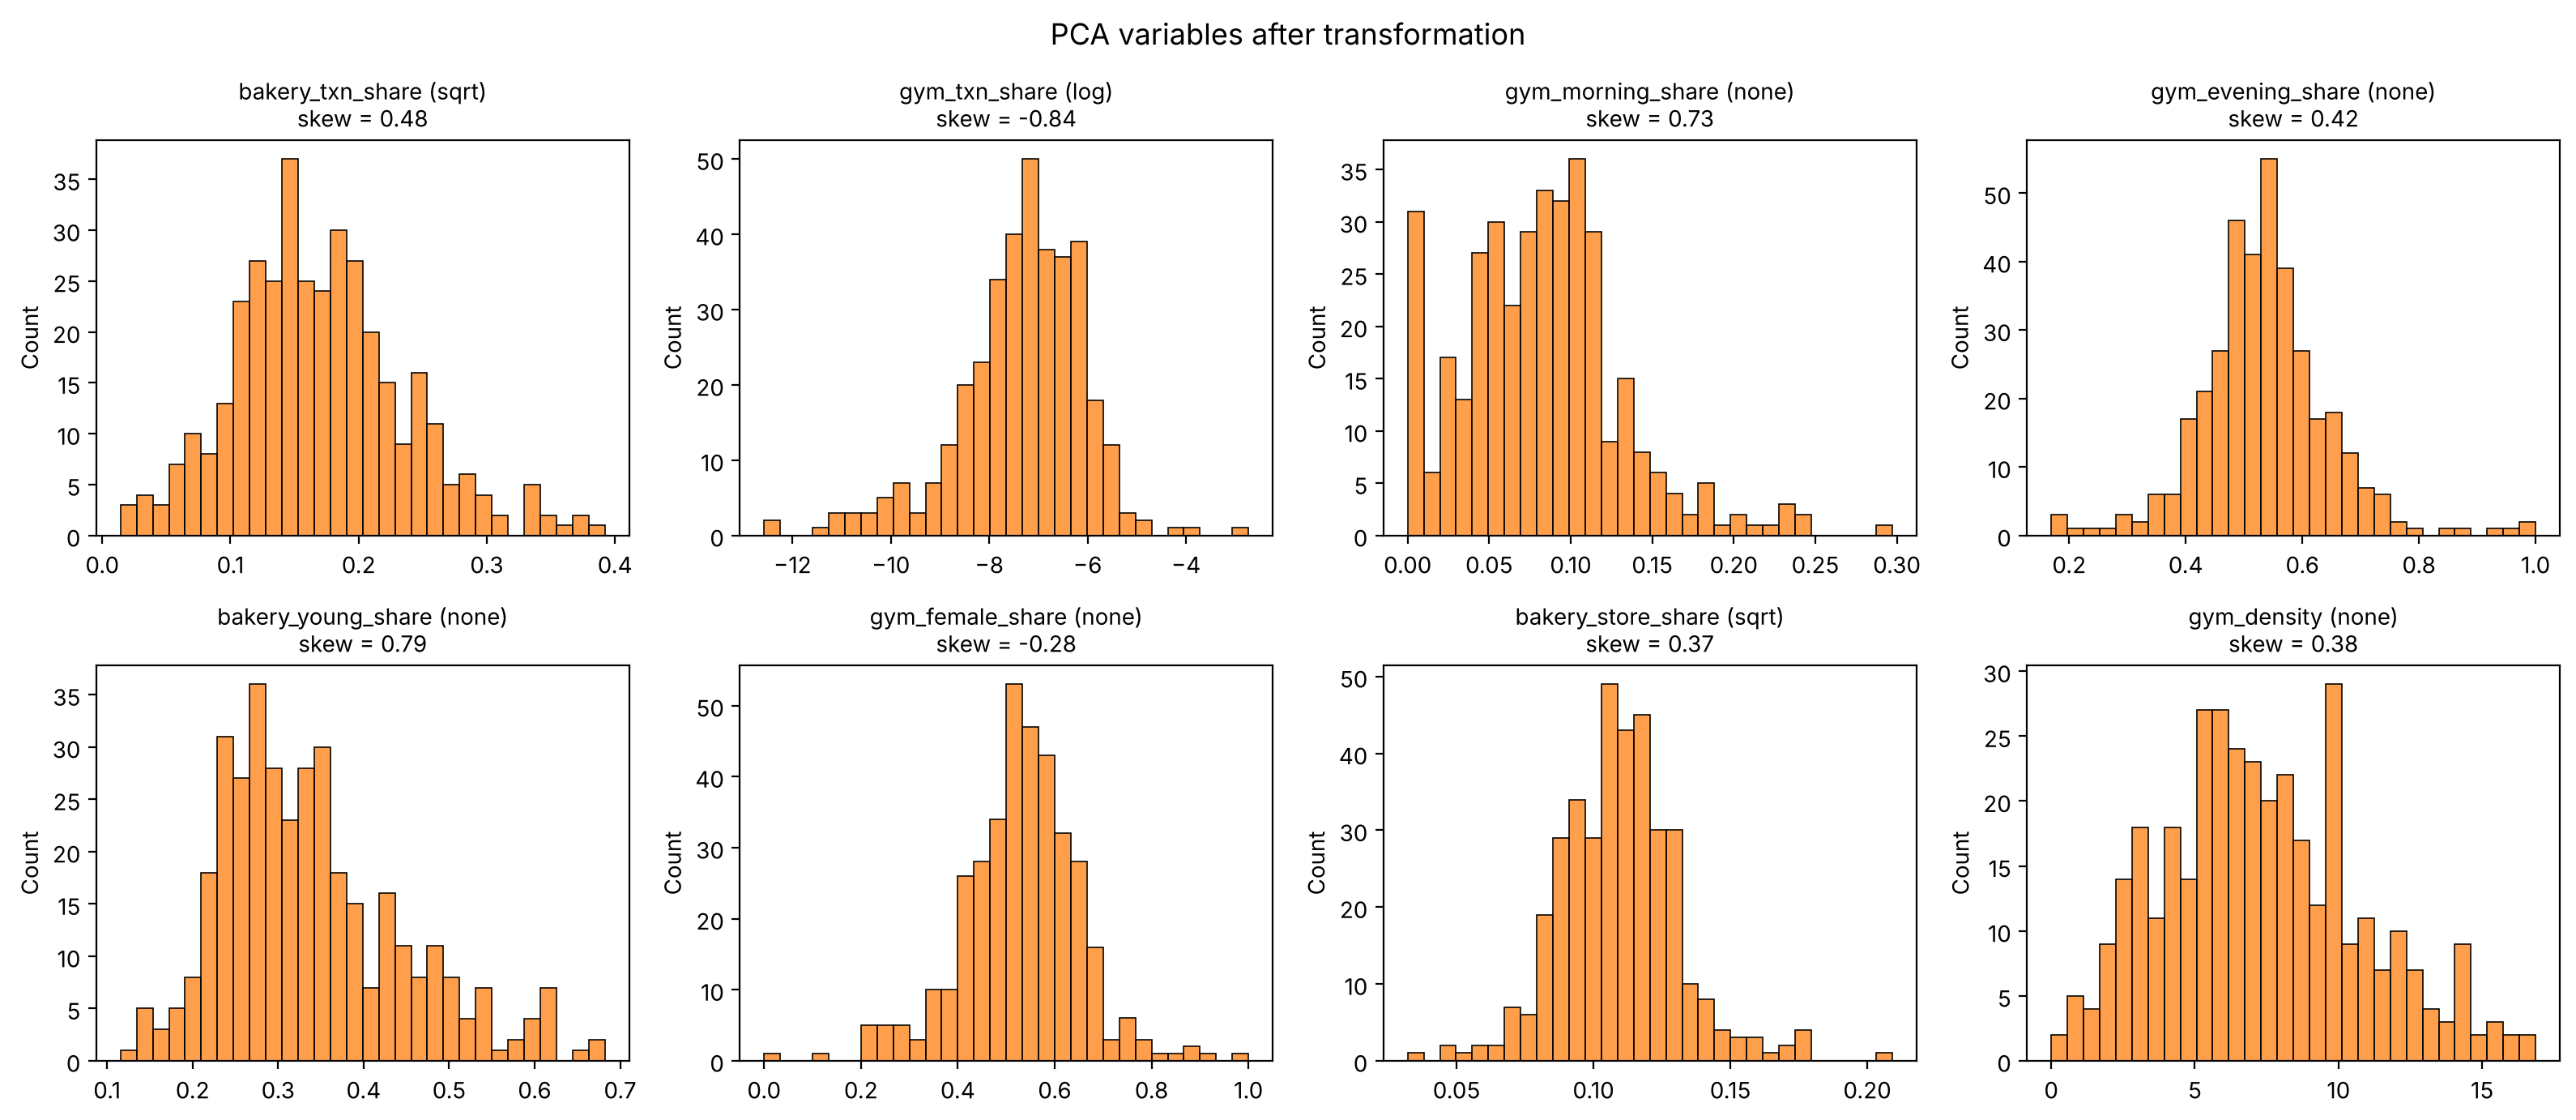

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, PCA_VARS):
    sns.histplot(X[col], ax=ax, bins=30, color="tab:orange")
    ax.set_title(f"{col} ({transform[col]})\nskew = {X[col].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
plt.suptitle("PCA variables after transformation", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES / "p1_distributions_after.png", dpi=150, bbox_inches="tight")
plt.show()

**Note on extreme shares.** A few 행정동 have a gym female share of 0% or 100%, or a gym evening share of 100%.
These are 행정동 with very few gym transactions (around 100 to 200 in the whole year), most likely a single small gym.
They are real values, so we keep them, but we will check them as outliers (Isolation Forest, as in the paper) before clustering.

In [19]:
gym_n = dong_clean["gym_total"]
extreme = dong_clean[(dong_clean["gym_female_share"].isin([0, 1])) | (dong_clean["gym_evening_share"] == 1)]
print("행정동 with fewer than 200 gym transactions in 2025:", (gym_n < 200).sum())
extreme[["Administrative_Dong_Name", "Borough", "gym_total", "gym_female_share", "gym_evening_share"]]

행정동 with fewer than 200 gym transactions in 2025: 13


,Administrative_Dong_Name,Borough,gym_total,gym_female_share,gym_evening_share
6,Cheonho 3-dong,Gangdong-gu,151.0,1.000000,0.94702
239,Eungam 3-dong,Eunpyeong-gu,107.0,0.000000,1.00000
363,Seongsu 2-ga 1-dong,Seongdong-gu,180.0,0.533333,1.00000


## 7. Standardize

PCA is **not scale invariant**. It finds the directions with the largest variance, so a variable measured on a bigger scale
(for example gym density, measured per 1,000 stores) would dominate variables that are shares between 0 and 1,
just because of its units. We standardize every variable to mean 0 and standard deviation 1 (z-score) so each one gets equal weight.

In [20]:
scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X), columns=PCA_VARS, index=dong_clean[KEY])

X_std.describe().T[["mean", "std"]].round(3)

,mean,std
bakery_txn_share,-0.0,1.001
gym_txn_share,0.0,1.001
gym_morning_share,0.0,1.001
gym_evening_share,-0.0,1.001
bakery_young_share,0.0,1.001
gym_female_share,0.0,1.001
bakery_store_share,0.0,1.001
gym_density,0.0,1.001


### Correlation between the PCA variables

PCA is only useful if the variables are correlated (otherwise every component just equals one variable).
We also check for pairs that are almost identical (|r| > 0.9), which would count the same thing twice.

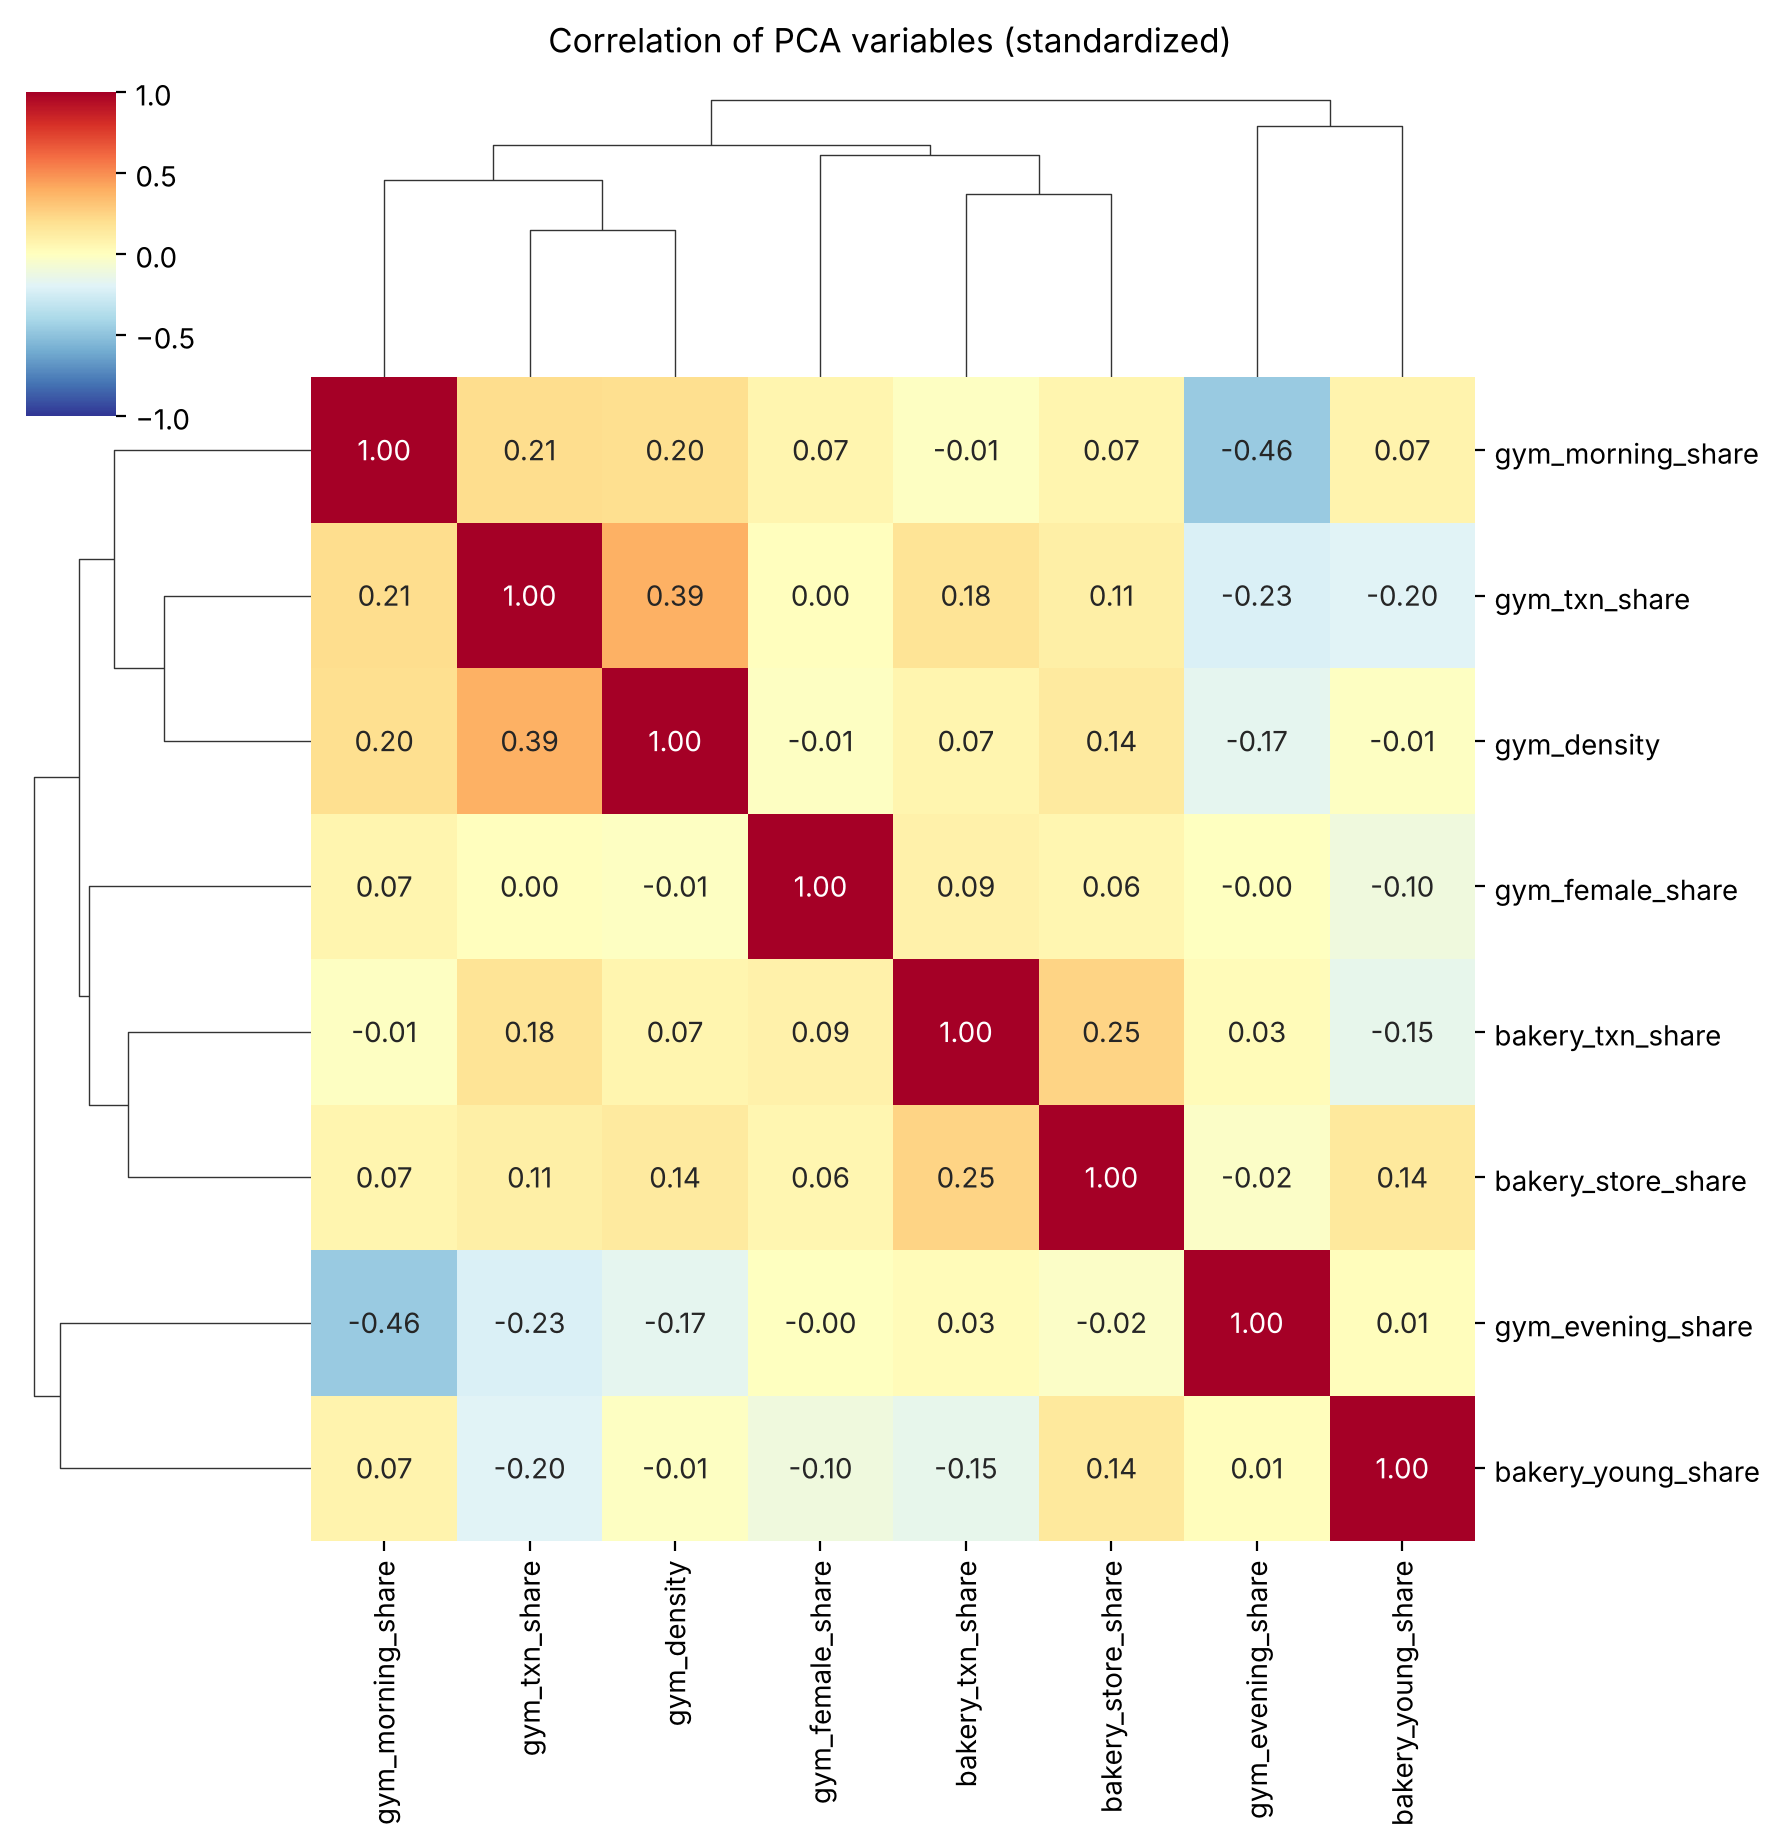

Pairs with |r| > 0.9: none


In [21]:
corr = X_std.corr()
g = sns.clustermap(corr, annot=True, fmt=".2f", cmap="RdYlBu_r", vmin=-1, vmax=1, figsize=(9, 9))
g.fig.suptitle("Correlation of PCA variables (standardized)", y=1.02)
g.savefig(FIGURES / "p1_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high = upper.stack()[upper.stack().abs() > 0.9]
print("Pairs with |r| > 0.9:", "none" if high.empty else high.round(2).to_dict())

## 8. Save the outputs for PCA

In [22]:
id_cols = [KEY, "Administrative_Dong_Name", "Borough_Code", "Borough"]

# Full table (raw values) for interpretation and coloring plots
dong_clean[id_cols + PCA_VARS + CONTEXT_VARS].to_csv(PROCESSED / "dong_features_2025.csv", index=False)

# Standardized matrix: the PCA input
X_std.reset_index().to_csv(PROCESSED / "dong_pca_input_standardized.csv", index=False)

print("Saved:", PROCESSED / "dong_features_2025.csv", dong_clean.shape[0], "rows")
print("Saved:", PROCESSED / "dong_pca_input_standardized.csv", X_std.shape)

Saved: ../data/processed/dong_features_2025.csv 365 rows
Saved: ../data/processed/dong_pca_input_standardized.csv (365, 8)


## Summary

| Item | Result |
|---|---|
| Unit of analysis | One 행정동, all of 2025 |
| Join key | `Administrative_Dong_Code` (8 digits); 자치구 = first 5 digits |
| Aggregation | Sales summed over 4 quarters; stores and population averaged; gyms counted by location |
| Missing values | 행정동 without bakery or gym transactions dropped (no imputation) |
| Transformation | Square root (skew 1 to 3) or log (skew > 3), then z-score standardization |
| PCA inputs | 8 variables (see `PCA_VARS`) |
| Held out of PCA | Obesity, resident and workplace population, workplace share |